# 数据结构与科学计算 · 第 06 讲
## 图、最短路径与非结构化 CFD 网格拓扑

> **课程定位**：面向已经学习 Python 基础、正在准备自行编写二维 CFD 求解器的学习者。本讲从数据结构原理出发，以实际数值计算问题作为应用练习。

**完成本讲后，你应该能够：**

1. 掌握图的点、边、有向/无向、带权/无权等概念；
2. 对比邻接表与邻接矩阵的空间成本；
3. 从二维三角形网格构造节点连接关系；
4. 使用 BFS/DFS 判断连通分量；
5. 用 Dijkstra 求解非负权最短路径，理解为什么 BFS 无法处理一般带权最短路径。

**预计学习时间**：90–130 分钟。所有核心示例可在 VS Code 的 Jupyter Notebook 中直接运行。

## 0. 使用方法与运行环境

1. 在 VS Code 打开此 `.ipynb`，右上角选择当前项目的 Python Kernel；
2. 使用 `Shift + Enter` 依次运行。修改代码后，建议 **Restart Kernel & Run All** 以消除旧变量干扰；
3. **练习单元以 `TODO` 留空**，后面会有逐项自动检查；未完成练习时显示“尚未通过”是预期行为；
4. 最后附有独立命名的 `_solution` 参考实现，不会覆盖你的练习函数；
5. 学习重点是“选择什么结构、为什么、代价是什么”，不只是背诵 API。

前两讲已安装 NumPy。本系列推荐运行 `uv pip install numpy scipy matplotlib ipykernel jupyter`。第 08 讲还需要 JAX：`uv pip install -U jax`（此命令默认安装适用于当前平台的发行版，GPU 支持视平台而定）。

In [1]:
import sys
print('Python:', sys.version.split()[0])
print('Notebook 已连接到 Python Kernel')

Python: 3.13.5
Notebook 已连接到 Python Kernel


## 1. CFD 中为什么需要“图”？

结构化网格能够通过下标直接定位邻居，比如 `(j,i±1)`。但在三角形、四边形或混合单元的**非结构化网格**中，邻接关系不能总由固定偏移推出，需要显式保存**拓扑**。

图的形式化定义：

$$G=(V,E),$$

- $V$：顶点集（网格节点、单元中心等）；
- $E$：边集（拓扑连接）；
- 可给边附加权重，例如几何距离、网格边长度、传输代价。

**不要混淆**：几何上的距离与 CFD 的流速、阻力、流动时间并不相等。最短路径是图论工具，不直接求解 Navier–Stokes 方程。

In [2]:
# 一个小型无向图（邻接列表）
graph = {
    0: [1, 2],
    1: [0, 3],
    2: [0, 3],
    3: [1, 2],
    4: []           # 与其他节点不连通
}
print('vertices:',len(graph))
print('degree of 0:',len(graph[0]))

vertices: 5
degree of 0: 2


## 2. 邻接表 vs 邻接矩阵

设顶点数 $|V|=n$，边数 $|E|=m$：

| 结构 | 空间（典型） | 查询某条边 | 列举某节点邻居 |
|:--|:--|:--|:--|
| 邻接矩阵 `n×n` | $O(n^2)$ | $O(1)$ | $O(n)$ |
| 邻接表 | $O(n+m)$ | 列表版最坏 $O(\deg v)$ | $O(\deg v)$ |
| `dict` 的邻居集合 | $O(n+m)$（额外对象开销） | 平均 $O(1)$ | $O(\deg v)$ |

对于二维局部网格，节点通常只和少数邻居相连，邻接矩阵大量元素为零。

In [3]:
import numpy as np
nodes = sorted(graph)
A = np.zeros((len(nodes), len(nodes)), dtype=np.int8)
for u, nbrs in graph.items():
    for v in nbrs:
        A[u,v] = 1
print('adjacency matrix:\n',A)
print('symmetric?', np.array_equal(A,A.T))

adjacency matrix:
 [[0 1 1 0 0]
 [1 0 0 1 0]
 [1 0 0 1 0]
 [0 1 1 0 0]
 [0 0 0 0 0]]
symmetric? True


## 3. 从二维三角形网格建立图

一个三角单元 `(a,b,c)` 贡献三条无向连接 `a-b`、`b-c`、`c-a`。注意邻接表只保留节点拓扑；实际 CFD 求解还需单元连接关系、法向量、面积等几何数据。

In [4]:
# 两个三角形构成的简单网格
points = np.array([[0,0],[1,0],[1,1],[0,1]], dtype=float)
triangles = [(0,1,2),(0,2,3)]

def build_mesh_neighbors(n_nodes, triangles):
    adjacency = {i:set() for i in range(n_nodes)}
    for a,b,c in triangles:
        for u,v in ((a,b),(b,c),(c,a)):
            adjacency[u].add(v)
            adjacency[v].add(u)
    return adjacency

mesh_adjacency = build_mesh_neighbors(len(points),triangles)
print('mesh adjacency:',mesh_adjacency)
assert mesh_adjacency[0] == {1,2,3}

mesh adjacency: {0: {1, 2, 3}, 1: {0, 2}, 2: {0, 1, 3}, 3: {0, 2}}


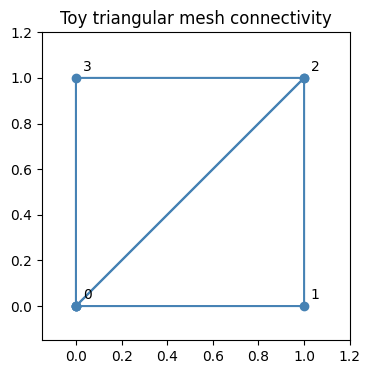

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5,4))
for tri in triangles:
    xy = points[list(tri)+[tri[0]]]
    ax.plot(xy[:,0],xy[:,1],'-o',color='steelblue')
for idx,(x,y) in enumerate(points):
    ax.text(x+0.03,y+0.03,str(idx))
ax.set(aspect='equal',xlim=(-0.15,1.2),ylim=(-0.15,1.2),title='Toy triangular mesh connectivity')
plt.show()

## 4. BFS 和 DFS 的复杂度回顾

第 02 讲介绍了队列版 BFS 和栈版 DFS。对于采用邻接表表示的图，遍历所有可达顶点和边的复杂度是：

$$O(|V|+|E|).$$

“已访问”的 `set` 可避免在存在环路的图上无限循环。连通分量用于检查网格是否被障碍物或数据错误分割成不相连的区域。

In [6]:
from collections import deque

def reachable_bfs(g, start):
    visited = {start}
    queue = deque([start])
    while queue:
        node = queue.popleft()
        for nxt in g.get(node,[]):
            if nxt not in visited:
                visited.add(nxt)
                queue.append(nxt)
    return visited

print('from 0:',reachable_bfs(graph,0))
print('from 4:',reachable_bfs(graph,4))

from 0: {0, 1, 2, 3}
from 4: {4}


## 5. 为什么一般带权图要用 Dijkstra？

BFS 按**边的条数**逐层扩展，因此只能保证无权图或**所有边权相同**的最短路径。边权不同但均非负时，可以使用 Dijkstra：

1. 维护当前已知的起点到各点的最小距离 `dist`；
2. 从最小堆取出当前代价最小的待探索节点；
3. 对邻居执行松弛 `alt = dist[u] + weight(u,v)`；
4. 如果有更短路径，更新距离并重新入堆。

使用 `heapq` 且容许过时队列项的常见实现，时间复杂度为 $O((|V|+|E|)\log |V|)$（典型上界，依赖具体实现）。**不能用于负权边**。

In [7]:
import heapq

weighted = {
    'S': {'A': 10, 'B': 1},
    'B': {'A': 2, 'T': 9},
    'A': {'T': 2},
    'T': {},
}

def dijkstra_demo(g, source):
    dist = {v: float('inf') for v in g}
    dist[source] = 0
    pq = [(0, source)]
    while pq:
        d,u = heapq.heappop(pq)
        if d > dist[u]:
            continue
        for v,w in g[u].items():
            if w < 0:
                raise ValueError('Dijkstra requires nonnegative weights')
            candidate = d + w
            if candidate < dist[v]:
                dist[v] = candidate
                heapq.heappush(pq,(candidate,v))
    return dist

print('distance from S:',dijkstra_demo(weighted,'S'))
print('S -> T via B -> A -> T costs 5, not 10')

distance from S: {'S': 0, 'B': 1, 'A': 3, 'T': 5}
S -> T via B -> A -> T costs 5, not 10


### 5.1 还原路径：除了距离，还需要 `parent`

松弛时记录 `parent[v] = u`；从终点沿父节点回溯到起点，再反转列表得到路径。这个思想与第 02 讲 BFS 一致，区别在于**选取下一个处理节点的方法**。

In [8]:
def shortest_path_with_parent(g, source, target):
    d = {v: float('inf') for v in g}
    parent = {source: None}
    d[source] = 0
    pq = [(0, 0, source)]
    seq = 1
    while pq:
        cost, _, u = heapq.heappop(pq)
        if cost != d[u]:
            continue
        if u == target:
            break
        for v, w in g[u].items():
            if w < 0:
                raise ValueError('negative weight')
            alt = cost+w
            if alt < d[v]:
                d[v] = alt
                parent[v] = u
                heapq.heappush(pq,(alt,seq,v))
                seq += 1
    if d[target] == float('inf'):
        return None
    path = []
    u = target
    while u is not None:
        path.append(u)
        u = parent[u]
    return path[::-1]

print('best path:',shortest_path_with_parent(weighted,'S','T'))

best path: ['S', 'B', 'A', 'T']


## 6. 从节点图到有限体积法

非结构有限体积法以单元为主时，更常建立“**单元与单元之间的邻接**”，并保存共享面：法向量、面积、面中心等。单元-面拓扑和边界条件共同决定离散通量公式。

仅凭“网格图相连”还无法得到合格 CFD 算法；离散几何量和控制方程仍是关键。

第 07 讲会介绍把局部相邻关系装配成稀疏线性方程组。

---
## 7. 编程练习

**练习 1**：实现 `edges_to_adjacency(n, edges)`：顶点编号 `0..n-1`，无向边列表 `(u,v)`，返回 `{i: set(neighbors)}`，包括孤立顶点。

In [9]:
def edges_to_adjacency(n, edges):
    # TODO: 处理重复边和自环；不应丢失孤立点
    return None

**练习 2**：实现 `connected_components(g)`：输入无向图邻接集合字典，返回 `list[set]`。分量顺序不限，分量内部无重复节点。

In [10]:
def connected_components(g):
    # TODO: 用 BFS 或 DFS 遍历每个尚未访问的节点
    return None

**练习 3**：实现 `shortest_distances(g, source)`：非负权邻接字典如 `{'A': {'B':2.0}, 'B':{}}`，返回从 source 到**全部顶点**的最小代价；不可达顶点值为 `float('inf')`。要求使用 `heapq`。

In [11]:
def shortest_distances(g, source):
    # TODO: Dijkstra；对负权重抛出 ValueError
    return None

## 练习自测

运行下方测试。`TODO` 未完成时出现“尚未通过”属于正常情况；逐项填入你的实现并再次运行。本讲的测试检查正确性与边界条件，性能优化可在通过后继续尝试。

In [12]:
def check(name, test_fn):
    try:
        test_fn()
        print(f"✅ {name}：通过")
    except Exception as exc:
        print(f"⬜ {name}：尚未通过 — {type(exc).__name__}: {exc}")

In [13]:
def test_ex1():
    expected = {0:{1},1:{0,2},2:{1},3:set()}
    assert edges_to_adjacency(4,[(0,1),(1,2),(0,1)]) == expected
    assert edges_to_adjacency(0,[]) == {}

def test_ex2():
    g = {0:{1},1:{0},2:set(),3:{4},4:{3}}
    comps = connected_components(g)
    assert isinstance(comps,list)
    assert {frozenset(s) for s in comps} == {frozenset({0,1}),frozenset({2}),frozenset({3,4})}

def test_ex3():
    g = {'S':{'A':10,'B':1},'A':{'T':2},'B':{'A':2,'T':9},'T':{},'X':{}}
    d = shortest_distances(g,'S')
    assert d['S'] == 0 and d['B'] == 1 and d['A'] == 3 and d['T'] == 5
    assert d['X'] == float('inf')
    try:
        shortest_distances({'S':{'T':-1},'T':{}},'S')
    except ValueError:
        pass
    else:
        assert False,'负权应抛出 ValueError'

check('练习 1 / 无向邻接表',test_ex1)
check('练习 2 / 连通分量',test_ex2)
check('练习 3 / Dijkstra',test_ex3)

⬜ 练习 1 / 无向邻接表：尚未通过 — AssertionError: 
⬜ 练习 2 / 连通分量：尚未通过 — AssertionError: 
⬜ 练习 3 / Dijkstra：尚未通过 — TypeError: 'NoneType' object is not subscriptable


## 8. 参考答案

In [14]:
def edges_to_adjacency_solution(n,edges):
    g = {i:set() for i in range(n)}
    for u,v in edges:
        g[u].add(v)
        g[v].add(u)
    return g

def connected_components_solution(g):
    visited = set()
    comps = []
    for start in g:
        if start in visited:
            continue
        component = set()
        q = deque([start])
        visited.add(start)
        while q:
            u = q.popleft()
            component.add(u)
            for v in g[u]:
                if v not in visited:
                    visited.add(v)
                    q.append(v)
        comps.append(component)
    return comps

def shortest_distances_solution(g,source):
    if source not in g:
        raise KeyError(source)
    d = {v:float('inf') for v in g}
    d[source] = 0
    seq = 0
    pq = [(0,seq,source)]
    while pq:
        cost,_,u = heapq.heappop(pq)
        if cost > d[u]:
            continue
        for v,w in g[u].items():
            if w < 0:
                raise ValueError('negative weight')
            alt = cost + w
            if alt < d[v]:
                d[v] = alt
                seq += 1
                heapq.heappush(pq,(alt,seq,v))
    return d

assert len(connected_components_solution(graph)) == 2
assert shortest_distances_solution(weighted,'S')['T'] == 5
print('✅ 参考答案自测通过')

✅ 参考答案自测通过


## 9. 综合实验：三角网格的加权节点图

用节点间的欧氏距离作为边权，计算图上沿网格边移动的最短距离。注意这是**几何图的路径长度**，不是流体颗粒经过该路径的时间。

In [15]:
def weighted_mesh_graph(points, triangles):
    neighbors = build_mesh_neighbors(len(points),triangles)
    return {
        u: {v: float(np.linalg.norm(points[u]-points[v])) for v in vs}
        for u,vs in neighbors.items()
    }

mesh_g = weighted_mesh_graph(points,triangles)
print('weighted neighbors of node 0:',mesh_g[0])
print('min path length 1→3:',round(dijkstra_demo(mesh_g,1)[3],3))

weighted neighbors of node 0: {1: 1.0, 2: 1.4142135623730951, 3: 1.0}
min path length 1→3: 2.0


## 10. 课末自测

1. 在什么条件下 BFS 给出最短路径？
2. 邻接矩阵与邻接表在百万节点局部连接网格上的内存差异为何巨大？
3. Dijkstra 为何不允许负边权？
4. 在 CFD 中，“节点相邻”和“单元共享一个面”是否同一件事？
5. 为什么 `set` 很适合构建拓扑，但数值离散矩阵最终应该压缩成稀疏格式？

**选做**：给多个三角单元建立“单元-单元”邻接图：先定义公共边，再根据共享边连接相邻单元。下一讲进入稀疏矩阵、COO、CSR 与 Poisson 方程。